# JurisEC — Notebook 3: Performance by Lexical Overlap and Document Length

**Goal.** Reproduce the stratified results of the paper (Section 6.2 and Fig. 9): how each system performs when a query and its response share few or many words, and when the response is short or long.

**What it does.**
1. Groups the queries into four quartiles by the word overlap between each query and its reference response, and reports R@1 for each system in each quartile.
2. Counts the tokens of every document, groups the queries into four quartiles by the length of their reference response, and reports R@1 in each quartile.
3. Tests whether the 512-token limit of E5-large explains its drop on long documents.
4. Draws the figure.

**Requirements.** A GPU and the `HF_TOKEN` secret in Colab (EmbeddingGemma is a gated model). The notebook is self-contained: it downloads the dataset and computes the embeddings, or reuses them if they are already in `cache_emb/`.

**Outputs** (in `results/`): `overlap_quartiles.csv`, `length_quartiles.csv`, `per_query.csv`, and the figure as PDF and PNG.

**Reproducibility note.** The random seed is fixed. Embeddings are computed in half precision, so scores may vary in the third decimal place depending on the hardware.


In [ ]:
%%capture
# matplotlib and scipy are NOT upgraded: Colab preloads them when the kernel starts, and
# upgrading them leaves old modules in memory against new files on disk.
# The preinstalled versions are used.
!pip install -q -U datasets rank_bm25 transformers sentence-transformers

In [ ]:
import os, re, json, unicodedata
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
import matplotlib as mpl
from datasets import load_dataset
from scipy.stats import rankdata

SEED   = 42
rng    = np.random.default_rng(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
CACHE  = "/content/cache_emb"
OUT    = "/content/results"
os.makedirs(CACHE, exist_ok=True); os.makedirs(OUT, exist_ok=True)

BLOQUE = 512
K      = 10
B_IC   = 2000        # bootstrap resamples for the confidence intervals of each group

EJE_J = ["Q1 (low)", "Q2", "Q3", "Q4 (high)"]
EJE_L = ["L1 (short)", "L2", "L3", "L4 (long)"]

# Hugging Face token: required for EmbeddingGemma (a gated model)
# and for the dataset if the repository is private.
try:
    from google.colab import userdata
    from huggingface_hub import login
    login(token=userdata.get("HF_TOKEN"))
except Exception as e:
    print("No Hugging Face token found in the Colab secrets (HF_TOKEN):", type(e).__name__)
print("Device:", DEVICE)

## 1. Data and relevance judgments

Loads the 5,536 queries with their official responses. Identical responses are collapsed into a single candidate document, which leaves 5,508 documents. Nearly identical queries (TF-IDF cosine similarity of 0.90 or higher) receive reciprocal relevance judgments: the response to one also counts as relevant for the other.


In [ ]:
ds = load_dataset("wilfredomartel/JurisEC")
ds = ds["train"] if "train" in ds else ds[list(ds.keys())[0]]
df = ds.to_pandas()

def limpia_texto(x):
    return x.strip() if isinstance(x, str) else ""

for col in ["consulta", "resolucion_consulta", "materia", "fuente"]:
    if col in df.columns: df[col] = df[col].map(limpia_texto)
df = df[(df["consulta"] != "") & (df["resolucion_consulta"] != "")].reset_index(drop=True)

texto_a_docid, corpus_ids, corpus_texts = {}, [], []
for t in df["resolucion_consulta"]:
    if t not in texto_a_docid:
        texto_a_docid[t] = f"d{len(corpus_texts)}"
        corpus_ids.append(texto_a_docid[t]); corpus_texts.append(t)
df["doc_id"] = df["resolucion_consulta"].map(texto_a_docid)
df["qid"]    = [f"q{i}" for i in range(len(df))]

qids     = df["qid"].tolist()
n_q, n_d = len(qids), len(corpus_ids)
pos_doc  = {d: i for i, d in enumerate(corpus_ids)}
doc_de_oro = df["doc_id"].map(pos_doc).to_numpy()
print(f"Queries: {n_q:,} | Unique documents: {n_d:,} | Collapsed duplicates: {len(df)-n_d}")
if (n_q, n_d) != (5536, 5508):
    print("WARNING: the paper reports 5,536 queries and 5,508 documents; this dataset gives different counts.")

Queries: 5,536 | Unique documents: 5,508 | Collapsed duplicates: 28


In [ ]:
def normaliza(t):
    '''Lowercases the text and removes accents.'''
    t = unicodedata.normalize("NFD", t.lower())
    return "".join(c for c in t if unicodedata.category(c) != "Mn")

# Nearly identical query pairs (TF-IDF cosine similarity >= 0.90).
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
vect = TfidfVectorizer(preprocessor=normaliza, token_pattern=r"[a-z0-9]{3,}")
M = vect.fit_transform(df["consulta"].tolist())
pares_gemelas = []
for ini in range(0, M.shape[0], 512):
    sim = np.asarray(cosine_similarity(M[ini:ini+512], M))
    for fila in range(sim.shape[0]):
        i = ini + fila; sim[fila, i] = -1.0
        j = int(sim[fila].argmax())
        if sim[fila, j] >= 0.90 and i < j: pares_gemelas.append((i, j))

qrels = {q: {d: 1} for q, d in zip(qids, df["doc_id"])}
for i, j in pares_gemelas:
    qrels[qids[i]][df["doc_id"].iloc[j]] = 1
    qrels[qids[j]][df["doc_id"].iloc[i]] = 1
json.dump(qrels, open(f"{OUT}/qrels.json", "w"))

relevantes = [np.array(sorted(pos_doc[d] for d in qrels[q]), dtype=np.int32) for q in qids]
n_rel      = np.array([len(r) for r in relevantes])
print(f"Nearly identical query pairs: {len(pares_gemelas)}")
print(f"Queries with more than one relevant document: {(n_rel > 1).sum()} ({(n_rel > 1).mean():.1%})")

Nearly identical query pairs: 29
Queries with more than one relevant document: 58 (1.0%)


## 2. Embeddings for the dense models

Encodes the queries and documents with E5-large, EmbeddingGemma-300M, and BGE-M3, using each model's maximum input length and prefixes. Embeddings already saved in `cache_emb/` are reused.


In [ ]:
from sentence_transformers import SentenceTransformer

queries_texts = df["consulta"].tolist()
MODELOS = {     # settings for each model
    "BGE-M3":         dict(repo="BAAI/bge-m3", archivos=("BGE-M3_Q.npy", "BGE-M3_D.npy"),
                           tokens=8192, lote=8,  pref_q="", pref_d=""),
    "E5-large":       dict(repo="intfloat/multilingual-e5-large", archivos=("E5_Q.npy", "E5_D.npy"),
                           tokens=512,  lote=32, pref_q="query: ", pref_d="passage: "),
    "EmbeddingGemma": dict(repo="google/embeddinggemma-300m", archivos=("GEMMA_Q.npy", "GEMMA_D.npy"),
                           tokens=2048, lote=16, pref_q="task: search result | query: ",
                           pref_d="title: none | text: "),
}

def cache_valida(cfg):
    fq, fd = (f"{CACHE}/{a}" for a in cfg["archivos"])
    if not (os.path.exists(fq) and os.path.exists(fd)): return False
    return (np.load(fq, mmap_mode="r").shape[0] == n_q and np.load(fd, mmap_mode="r").shape[0] == n_d)

for nombre, cfg in MODELOS.items():
    if cache_valida(cfg):
        print(f"{nombre}: embeddings already saved; not recomputed."); continue
    assert DEVICE == "cuda", ("Embeddings are missing and no GPU is available. Enable a GPU in "
                              "Runtime > Change runtime type.")
    if nombre == "EmbeddingGemma":
        dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float32
    else:
        dtype = torch.float16
    modelo = SentenceTransformer(cfg["repo"], device=DEVICE, model_kwargs={"torch_dtype": dtype})
    modelo.max_seq_length = cfg["tokens"]
    if nombre == "EmbeddingGemma":      # prompts must match the official model card
        assert modelo.prompts.get("query") == cfg["pref_q"], modelo.prompts
        assert modelo.prompts.get("document") == cfg["pref_d"], modelo.prompts
    def codifica(textos):
        return modelo.encode(textos, batch_size=cfg["lote"], normalize_embeddings=True,
                             show_progress_bar=True, convert_to_numpy=True).astype(np.float32)
    np.save(f"{CACHE}/{cfg['archivos'][0]}", codifica([cfg["pref_q"] + q for q in queries_texts]))
    np.save(f"{CACHE}/{cfg['archivos'][1]}", codifica([cfg["pref_d"] + d for d in corpus_texts]))
    del modelo; torch.cuda.empty_cache()
    print(f"{nombre}: embeddings computed and saved to {CACHE}.")

## 3. Word overlap between each query and its response

Computes the Jaccard overlap between the content words of each query and those of its reference response. Content words are lowercased, without accents, at least three characters long, and not Spanish stop words. The queries are then split into four quartiles, from Q1 (lowest overlap) to Q4 (highest). Queries with the same overlap always fall in the same quartile.


In [ ]:
STOPWORDS = set(("de la el en y a los del las un una que por con para es al se su o e lo como mas "
"pero sus le ya fue este si porque esta entre cuando muy sin sobre tambien me hasta hay donde quien "
"desde todo nos durante todos uno les ni contra otros ese eso ante ellos esto mi antes algunos unos "
"yo otro otras otra tanto esa estos mucho quienes nada muchos cual sea poco ella estar haber estas "
"estaba estamos algunas algo nosotros").split())

def palabras_contenido(texto):
    return {w for w in re.findall(r"[a-z0-9]+", normaliza(texto))
            if len(w) > 2 and w not in STOPWORDS}

sets_consulta = [palabras_contenido(c) for c in df["consulta"]]
sets_oro      = [palabras_contenido(corpus_texts[j]) for j in doc_de_oro]
jaccard = np.array([len(a & b) / len(a | b) if (a | b) else 0.0
                    for a, b in zip(sets_consulta, sets_oro)])

print(f"Jaccard: median = {np.median(jaccard):.3f} | "
      f"mean = {jaccard.mean():.3f} | "
      f"J < 0.05 = {(jaccard < 0.05).mean():.1%}")

cuartil_J = pd.Categorical(
    pd.qcut(rankdata(jaccard, method="average"), 4, labels=EJE_J),
    categories=EJE_J, ordered=True)
print(pd.Series(cuartil_J).value_counts(sort=False).to_string())

Jaccard: median = 0.143 | mean = 0.154 | J < 0.05 = 8.3%
Q1 (low)     1395
Q2           1380
Q3           1377
Q4 (high)    1384


## 4. Per-query metrics

Ranks all 5,508 documents for each query and computes nDCG@10, Acc@1, and R@1 per query for the four systems. R@1 is the fraction of a query's relevant documents that is ranked first. The table compares the mean nDCG@10 with the value in Table 6 of the paper and should show `ok` for all four systems.


In [ ]:
ARCHIVOS = {"E5-large":       ("E5_Q.npy",     "E5_D.npy"),
            "EmbeddingGemma": ("GEMMA_Q.npy",  "GEMMA_D.npy"),
            "BGE-M3":         ("BGE-M3_Q.npy", "BGE-M3_D.npy")}
SISTEMAS = ["BM25", "E5-large", "EmbeddingGemma", "BGE-M3"]

def fuente_densa(nombre):
    fq, fd = ARCHIVOS[nombre]
    Q = np.load(f"{CACHE}/{fq}").astype(np.float32)
    D = np.load(f"{CACHE}/{fd}").astype(np.float32)
    assert Q.shape[0] == n_q and D.shape[0] == n_d, (Q.shape, D.shape, n_q, n_d)
    for ini in range(0, n_q, BLOQUE):
        yield ini, Q[ini:ini+BLOQUE] @ D.T

def fuente_bm25():
    from rank_bm25 import BM25Okapi
    def tokenize(texto):
        return [w for w in re.findall(r"[a-z0-9]+", normaliza(texto))
                if len(w) > 2 and w not in STOPWORDS]
    indice = BM25Okapi([tokenize(d) for d in corpus_texts])
    consultas_tok = [tokenize(c) for c in df["consulta"]]
    for ini in range(0, n_q, BLOQUE):
        yield ini, np.vstack([indice.get_scores(t)
                              for t in consultas_tok[ini:ini+BLOQUE]]).astype(np.float32)

def fuente(nombre):
    return fuente_bm25() if nombre == "BM25" else fuente_densa(nombre)

DESCUENTO = 1.0 / np.log2(np.arange(2, K + 2))
IDCG      = np.array([DESCUENTO[:min(K, r)].sum() for r in range(0, n_d + 1)][:K + 1])

def recorrer(nombre):
    rango  = np.empty(n_q, np.int32)
    r1     = np.empty(n_q, np.float64)
    ndcg10 = np.empty(n_q, np.float64)
    for ini, S in fuente(nombre):
        for f in range(S.shape[0]):
            i, fila = ini + f, S[f]
            rel   = relevantes[i]
            s_oro = fila[rel].max()
            rango[i] = 1 + int((fila > s_oro).sum())
            top = np.argpartition(-fila, K)[:K]
            top = top[np.argsort(-fila[top], kind="stable")]
            ganancias = np.isin(top, rel).astype(np.float64)
            r1[i]     = ganancias[0] / len(rel)
            ndcg10[i] = (ganancias * DESCUENTO).sum() / IDCG[min(K, len(rel))]
    return dict(rango=rango, exito1=(rango == 1), r1=r1, ndcg10=ndcg10)

R = {}
TABLE_6 = {"BM25": 0.767, "E5-large": 0.753, "EmbeddingGemma": 0.782, "BGE-M3": 0.774}
print(f"{'System':<16}{'nDCG@10':>9}{'Table 6':>9}{'Acc@1':>8}{'R@1':>8}")
for s in SISTEMAS:
    R[s] = recorrer(s)
    ok = "ok" if abs(R[s]["ndcg10"].mean() - TABLE_6[s]) < 5e-3 else "CHECK!"
    print(f"{s:<16}{R[s]['ndcg10'].mean():>9.4f}{TABLE_6[s]:>9.3f}"
          f"{R[s]['exito1'].mean():>8.4f}{R[s]['r1'].mean():>8.4f}  {ok}")

System            nDCG@10  Table 6   Acc@1     R@1
BM25               0.7671    0.767  0.6581  0.6522  ok
E5-large           0.7525    0.753  0.6479  0.6435  ok
EmbeddingGemma     0.7816    0.782  0.6808  0.6764  ok
BGE-M3             0.7748    0.774  0.6685  0.6643  ok


## 5. Performance by word overlap

Reports R@1 for each system in each overlap quartile, with 95% bootstrap confidence intervals, and the difference between the best dense model and BM25. It also reports the queries with almost no overlap (J < 0.05) separately.


In [ ]:
def ic_bootstrap_media(x, B=B_IC):
    '''95% percentile confidence interval of the mean of x, by resampling with replacement.'''
    idx = rng.integers(0, len(x), size=(B, len(x)))
    medias = x[idx].mean(axis=1)
    return np.percentile(medias, [2.5, 97.5])

def tabla_por_estrato(etiquetas, orden, nombre_eje):
    '''R@1 (with bootstrap CI), Acc@1, and the gain of the best dense model, for each group in a fixed order.'''
    filas = []
    et = np.asarray(etiquetas)
    for est in orden:
        m = (et == est); n = int(m.sum())
        fila = {nombre_eje: est, "n": n}
        for s in SISTEMAS:
            x = R[s]["r1"][m]
            lo, hi = ic_bootstrap_media(x)
            fila[s] = x.mean()
            fila[f"{s} CI"] = f"[{lo:.3f}, {hi:.3f}]"
            fila[f"{s} Acc@1"] = R[s]["exito1"][m].mean()
        mejor_denso = max(SISTEMAS[1:], key=lambda s: R[s]["r1"][m].mean())
        fila["best dense − BM25"] = (R[mejor_denso]["r1"][m].mean()
                                      - R["BM25"]["r1"][m].mean())
        filas.append(fila)
    return pd.DataFrame(filas)

tabla_a = tabla_por_estrato(cuartil_J, EJE_J, "Jaccard quartile")
cols = ["Jaccard quartile", "n"] + SISTEMAS + ["best dense − BM25"]
print(tabla_a[cols].round(3).to_string(index=False))
tabla_a.to_csv(f"{OUT}/overlap_quartiles.csv", index=False)

extremo = jaccard < 0.05
print(f"\nSubset J < 0.05: n = {extremo.sum()} ({extremo.mean():.1%})")
print(f"{'System':<16}{'R@1 (J<0.05)':>14}{'95% CI':>18}{'R@1 (rest)':>13}{'Δ':>8}")
for s in SISTEMAS:
    dentro, fuera = R[s]["r1"][extremo].mean(), R[s]["r1"][~extremo].mean()
    lo, hi = ic_bootstrap_media(R[s]["r1"][extremo])
    print(f"{s:<16}{dentro:>14.3f}   [{lo:.3f}, {hi:.3f}]{fuera:>13.3f}{dentro-fuera:>8.3f}")

Jaccard quartile    n  BM25  E5-large  EmbeddingGemma  BGE-M3  best dense − BM25
        Q1 (low) 1395 0.307     0.296           0.372   0.343              0.065
              Q2 1380 0.618     0.623           0.666   0.671              0.053
              Q3 1377 0.788     0.783           0.791   0.777              0.003
       Q4 (high) 1384 0.898     0.876           0.879   0.870             -0.019

Subset J < 0.05: n = 459 (8.3%)
System            R@1 (J<0.05)            95% CI   R@1 (rest)       Δ
BM25                     0.157   [0.125, 0.192]        0.697  -0.540
E5-large                 0.136   [0.106, 0.169]        0.689  -0.553
EmbeddingGemma           0.234   [0.196, 0.273]        0.716  -0.482
BGE-M3                   0.188   [0.155, 0.225]        0.707  -0.519


## 6. Document length in tokens and truncation

Counts the tokens of every document with each model's tokenizer and reports how many documents exceed the model's input limit. The queries are split into four quartiles by the length of their reference response, from L1 (shortest) to L4 (longest), and the share of responses truncated by E5-large is reported for each quartile.


In [ ]:
from transformers import AutoTokenizer

def cuenta_tokens(nombre_modelo, textos, prefijo=""):
    tok = AutoTokenizer.from_pretrained(nombre_modelo)
    n = np.empty(len(textos), np.int32)
    for ini in range(0, len(textos), 256):
        ids = tok([prefijo + t for t in textos[ini:ini+256]],
                  add_special_tokens=True, truncation=False, padding=False)["input_ids"]
        n[ini:ini+256] = [len(x) for x in ids]
    return n

VENTANAS = {"E5-large": 512, "EmbeddingGemma": 2048, "BGE-M3": 8192}
tokens_doc = {}
tokens_doc["E5-large"] = cuenta_tokens("intfloat/multilingual-e5-large",
                                       corpus_texts, prefijo="passage: ")
tokens_doc["BGE-M3"]   = cuenta_tokens("BAAI/bge-m3", corpus_texts)
try:
    tokens_doc["EmbeddingGemma"] = cuenta_tokens("google/embeddinggemma-300m",
                                                 corpus_texts, prefijo="title: none | text: ")
except Exception as e:
    print(f"[warning] EmbeddingGemma tokenizer not available ({type(e).__name__}); "
          "it is a gated model and needs HF_TOKEN. Its token count is skipped.")

print(f"\n{'Model':<16}{'window':>8}{'median':>9}{'p90':>7}{'p99':>7}{'% truncated':>13}")
for m, toks in tokens_doc.items():
    v = VENTANAS[m]
    print(f"{m:<16}{v:>8}{int(np.median(toks)):>9}{int(np.percentile(toks,90)):>7}"
          f"{int(np.percentile(toks,99)):>7}{100*(toks > v).mean():>12.1f}%")

toks_oro = tokens_doc["E5-large"][doc_de_oro]
cuartil_L = pd.Categorical(
    pd.qcut(rankdata(toks_oro, method="average"), 4, labels=EJE_L),
    categories=EJE_L, ordered=True)
truncado = toks_oro > VENTANAS["E5-large"]

print(f"\nReference documents > 512 E5 tokens: {truncado.sum()} ({truncado.mean():.1%})")
print("\n% of reference documents truncated by E5, by length quartile:")
pct_trunc = {}
for q in EJE_L:
    m = np.asarray(cuartil_L) == q
    pct_trunc[q] = truncado[m].mean()
    print(f"  {q:<12} {100*pct_trunc[q]:>6.1f}%   (median tokens: {int(np.median(toks_oro[m]))})")


Model             window   median    p90    p99  % truncated
E5-large             512      217    465   1128         7.8%
BGE-M3              8192      215    463   1126         0.0%
EmbeddingGemma      2048      225    467   1112         0.1%

Reference documents > 512 E5 tokens: 431 (7.8%)

% of reference documents truncated by E5, by length quartile:
  L1 (short)      0.0%   (median tokens: 104)
  L2              0.0%   (median tokens: 177)
  L3              0.0%   (median tokens: 271)
  L4 (long)      31.3%   (median tokens: 432)


## 7. Does truncation explain the drop of E5-large?

Compares the gap between E5-large and BGE-M3 on truncated and non-truncated reference responses (a difference in differences), with a two-sided permutation test (10,000 permutations). It also compares each dense model in L2, where nothing is truncated, with L4.


In [ ]:
def brecha(m):
    return R["E5-large"]["r1"][m].mean() - R["BGE-M3"]["r1"][m].mean()

print(f"{'Group':<22}{'n':>6}{'R@1 E5':>9}{'R@1 BGE':>9}{'gap':>9}")
for nombre, m in [("not truncated (≤512)", ~truncado), ("truncated (>512)", truncado)]:
    print(f"{nombre:<22}{int(m.sum()):>6}{R['E5-large']['r1'][m].mean():>9.3f}"
          f"{R['BGE-M3']['r1'][m].mean():>9.3f}{brecha(m):>9.3f}")
did = brecha(truncado) - brecha(~truncado)
print(f"\nDifference in differences (truncated − not truncated): {did:+.3f}")

d_por_consulta = R["E5-large"]["r1"] - R["BGE-M3"]["r1"]
obs = d_por_consulta[truncado].mean() - d_por_consulta[~truncado].mean()
b = 0
for _ in range(10_000):
    perm = rng.permutation(truncado)
    if abs(d_por_consulta[perm].mean() - d_por_consulta[~perm].mean()) >= abs(obs): b += 1
print(f"p (two-sided permutation test, 10,000) = {(b+1)/10_001:.4f}")

# Each dense model in L2 versus L4: separates truncation from a general decline with length
print("\nR@1 per model in L2 (nothing truncated) versus L4:")
mL2 = np.asarray(cuartil_L) == "L2"; mL4 = np.asarray(cuartil_L) == "L4 (long)"
for s in SISTEMAS[1:]:
    print(f"  {s:<16} L2 = {R[s]['r1'][mL2].mean():.3f} | L4 = {R[s]['r1'][mL4].mean():.3f} "
          f"| Δ = {R[s]['r1'][mL4].mean()-R[s]['r1'][mL2].mean():+.3f}")

Group                      n   R@1 E5  R@1 BGE      gap
not truncated (≤512)    5105    0.659    0.676   -0.017
truncated (>512)         431    0.456    0.524   -0.068

Difference in differences (truncated − not truncated): -0.052
p (two-sided permutation test, 10,000) = 0.0111

R@1 per model in L2 (nothing truncated) versus L4:
  E5-large         L2 = 0.728 | L4 = 0.622 | Δ = -0.106
  EmbeddingGemma   L2 = 0.718 | L4 = 0.721 | Δ = +0.003
  BGE-M3           L2 = 0.718 | L4 = 0.664 | Δ = -0.054


## 8. Performance by document length, figure, and export

Reports R@1 for each system in each length quartile, draws the two-panel figure (Fig. 9 of the paper), and saves the tables, the per-query results, and the figure. Error bars are 95% bootstrap confidence intervals.


In [ ]:
tabla_b = tabla_por_estrato(cuartil_L, EJE_L, "length quartile")
cols = ["length quartile", "n"] + SISTEMAS + ["best dense − BM25"]
print(tabla_b[cols].round(3).to_string(index=False))
tabla_b.to_csv(f"{OUT}/length_quartiles.csv", index=False)

length quartile    n  BM25  E5-large  EmbeddingGemma  BGE-M3  best dense − BM25
     L1 (short) 1393 0.491     0.515           0.520   0.547              0.056
             L2 1388 0.648     0.728           0.718   0.718              0.080
             L3 1379 0.731     0.710           0.747   0.728              0.016
      L4 (long) 1376 0.740     0.622           0.721   0.664             -0.019


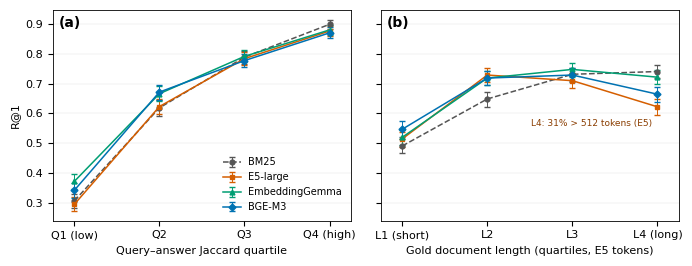

Saved to /content/results: overlap_quartiles.csv, length_quartiles.csv, per_query.csv, fig_stratification.pdf/.png


In [ ]:
COLOR  = {"BM25": "#555555", "E5-large": "#D55E00",
          "EmbeddingGemma": "#009E73", "BGE-M3": "#0072B2"}
MARCA  = {"BM25": "o", "E5-large": "s", "EmbeddingGemma": "^", "BGE-M3": "D"}
ESTILO = {"BM25": "--", "E5-large": "-", "EmbeddingGemma": "-", "BGE-M3": "-"}

mpl.rcParams.update({"font.size": 8, "axes.linewidth": 0.6, "legend.frameon": False})
fig, ax = plt.subplots(1, 2, figsize=(7.0, 2.7), sharey=True)

for k, (tabla, eje, etiquetas, xlab) in enumerate([
        (tabla_a, EJE_J, cuartil_J, "Query–answer Jaccard quartile"),
        (tabla_b, EJE_L, cuartil_L, "Gold document length (quartiles, E5 tokens)")]):
    d = tabla.set_index(tabla.columns[0]).loc[eje]
    for s in SISTEMAS:
        y = d[s].to_numpy()
        e = np.array([[float(v) for v in re.findall(r"[\d.]+", t)] for t in d[f"{s} CI"]])
        yerr = np.vstack([y - e[:, 0], e[:, 1] - y]); yerr[yerr < 0] = 0
        ax[k].errorbar(range(4), y, yerr=yerr, color=COLOR[s], marker=MARCA[s],
                       ls=ESTILO[s], ms=3.5, lw=1.1, capsize=2, elinewidth=0.7,
                       label=s if k == 0 else None)
    ax[k].set_xticks(range(4)); ax[k].set_xticklabels(eje)
    ax[k].set_xlabel(xlab)
    ax[k].text(0.02, 0.97, f"({chr(97+k)})", transform=ax[k].transAxes,
               fontsize=10, fontweight="bold", va="top")
    ax[k].set_xlim(-0.25, 3.25); ax[k].grid(axis="y", lw=0.3, alpha=0.4)

ax[0].set_ylabel("R@1")
ax[0].legend(fontsize=7, loc="lower right", handlelength=1.8)

# Truncation note, based on the percentages computed in Section 6:
sombreados = [i for i, q in enumerate(EJE_L) if pct_trunc[q] > 0.5]
if sombreados:
    ax[1].axvspan(min(sombreados) - 0.5, 3.25, color="#D55E00", alpha=0.07, lw=0)
    q_ref = EJE_L[min(sombreados)]
    ax[1].text(np.mean([min(sombreados), 3.1]), ax[1].get_ylim()[0] + 0.02,
               f"{100*pct_trunc['L4 (long)']:.0f}% > 512 tokens (E5)",
               ha="center", fontsize=6.5, color="#8a3d00")
else:
    ax[1].annotate(f"L4: {100*pct_trunc['L4 (long)']:.0f}% > 512 tokens (E5)",
                   (3, tabla_b.set_index('length quartile').loc['L4 (long)', 'E5-large']),
                   textcoords="offset points", xytext=(-4, -14),
                   fontsize=6.5, color="#8a3d00", ha="right")

plt.tight_layout()
plt.savefig(f"{OUT}/fig_stratification.pdf", bbox_inches="tight")
plt.savefig(f"{OUT}/fig_stratification_600dpi.png", bbox_inches="tight", dpi=600)
plt.show()

detalle = pd.DataFrame({
    "qid": qids, "fuente": df["fuente"], "materia": df["materia"],
    "jaccard": jaccard, "jaccard_quartile": cuartil_J,
    "reference_tokens_e5": toks_oro, "length_quartile": cuartil_L,
    "reference_truncated_e5": truncado, "n_relevant": n_rel})
for s in SISTEMAS:
    detalle[f"{s}_r1"], detalle[f"{s}_rank"] = R[s]["r1"], R[s]["rango"]
detalle.to_csv(f"{OUT}/per_query.csv", index=False)
print(f"Saved to {OUT}: overlap_quartiles.csv, length_quartiles.csv, per_query.csv, fig_stratification.pdf/.png")

## Notes

- R@1 is the metric used in the figure. For the queries with two relevant documents it can be at most 0.5, so its mean is slightly lower than Acc@1.
- Confidence intervals are 95% percentile bootstrap intervals over queries (2,000 resamples).
- Length quartiles use the E5 token count of each query's reference response.
